# A random walk and partial differential equations

*Beyond the exercises — sections 6.3 and 6.4 of the scriptum.*

---

In the notebook `ch06_markov_linear_equations` we solved a system of linear equations with a random
walk. A discretized partial differential equation **is** a system of linear equations, so the same
thing has to work there too. And it does — only in a much nicer form, because the walk has a vivid
physical meaning.

- the **Dirichlet problem** for the Laplace equation: the value at a point = the average over its
  neighbourhood
- the **walk on a lattice**: $u(x) = E\,[\,g(\text{the place where the walk leaves the region})\,]$
- the **Poisson equation** with a source: a contribution collected along the way is added
- the **walk on spheres**: how to get rid of the lattice and be two orders of magnitude faster

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results

## 1. The Dirichlet problem and the mean-value property

We are looking for $u$ on a region $G$ (we take the unit square) satisfying

$$\Delta u = 0 \ \text{ inside } G, \qquad u = g \ \text{ on the boundary.}$$

Replacing the second derivatives by differences on a lattice of step $h$, the five-point formula gives

$$\frac{u_{i+1,j} + u_{i-1,j} + u_{i,j+1} + u_{i,j-1} - 4u_{ij}}{h^2} = 0
\qquad\Longleftrightarrow\qquad
u_{ij} = \frac{u_{i+1,j} + u_{i-1,j} + u_{i,j+1} + u_{i,j-1}}{4}.$$

In words: **the value at a node is the average of the values at its four neighbours.** From there it
is a single step to the stochastic interpretation. The average over four neighbours is, after all, the
expectation over a randomly chosen neighbour:

$$u(x) = E\big[\,u(\text{a random neighbour})\,\big].$$

Repeating the argument, after $k$ steps we get $u(x) = E[u(X_k)]$ for a random walk $X_k$. As soon as
the walk hits the boundary, we know the value — it is $g$. So

$$\boxed{\,u(x) = E\big[\,g(X_T)\,\big]\,}$$

where $T$ is the moment the boundary is first reached. The solution at a point $x$ is **the
expectation of the boundary condition at the place where a random walk from $x$ leaves the region.**

### How to verify it

We need a problem with a known solution. The function $u(x,y) = x^2 - y^2$ is harmonic
($\Delta u = 2 - 2 = 0$), and on top of that the five-point formula is **exact** on it — the
discretization error is zero, because the fourth derivatives are zero. So we set $g = u$ on the
boundary and the same thing has to come out inside.

In [2]:
def g_harmonic(x, y):
    '''The boundary condition from the harmonic function u = x² - y².'''
    return x * x - y * y


def lattice_walk(x0, y0, h, g, f=None, N=20_000):
    '''u(x0,y0) as the expectation of g at the place where the square is left.

    f != None solves the Poisson equation Δu = f: along the way, -h²f/4 is collected per step.
    Returns (estimate, standard error, average number of steps).
    '''
    s = s2 = 0.0
    total_steps = 0
    for _ in range(N):
        x, y, acc, steps = x0, y0, 0.0, 0
        while 0 < x < 1 and 0 < y < 1:
            if f is not None:
                acc -= h * h * f(x, y) / 4.0
            direction = random.randrange(4)
            if direction == 0:
                x += h
            elif direction == 1:
                x -= h
            elif direction == 2:
                y += h
            else:
                y -= h
            x, y = round(x, 9), round(y, 9)
            steps += 1
        v = acc + g(x, y)
        s += v
        s2 += v * v
        total_steps += steps
    m = s / N
    return m, math.sqrt(max(s2 / N - m * m, 0.0) / N), total_steps / N


h = 1 / 40
print(f"The Laplace equation, lattice h = 1/{round(1/h)}")
print(f"{'point':>14s} {'walk':>22s} {'exact':>10s} {'steps':>8s}")
for px, py in ((0.5, 0.5), (0.25, 0.75), (0.1, 0.5), (0.5, 0.9)):
    m, se, steps = lattice_walk(px, py, h, g_harmonic)
    print(f"({px:.2f}, {py:.2f}) {m:>14.5f} +- {se:<6.5f} {g_harmonic(px, py):>10.5f} {steps:>8.0f}")
    assert abs(m - g_harmonic(px, py)) < 5 * se

The Laplace equation, lattice h = 1/40
         point                   walk      exact    steps


(0.50, 0.50)       -0.00059 +- 0.00411    0.00000      467


(0.25, 0.75)       -0.49702 +- 0.00336   -0.50000      292


(0.10, 0.50)       -0.23923 +- 0.00222   -0.24000      186


(0.50, 0.90)       -0.55600 +- 0.00308   -0.56000      190


It fits everywhere. Notice the last column: at $h = 1/40$ a walk from the middle of the square takes
several hundred steps, while one from a point near the edge takes less than half as many. That makes
sense — and at the same time it hints at where the method will be expensive.

## 2. What the walk actually sees

Let us draw a few walks and the distribution of the places where they end. It is precisely this
distribution (it is called the **harmonic measure**) that decides how much each part of the boundary
contributes to the result.

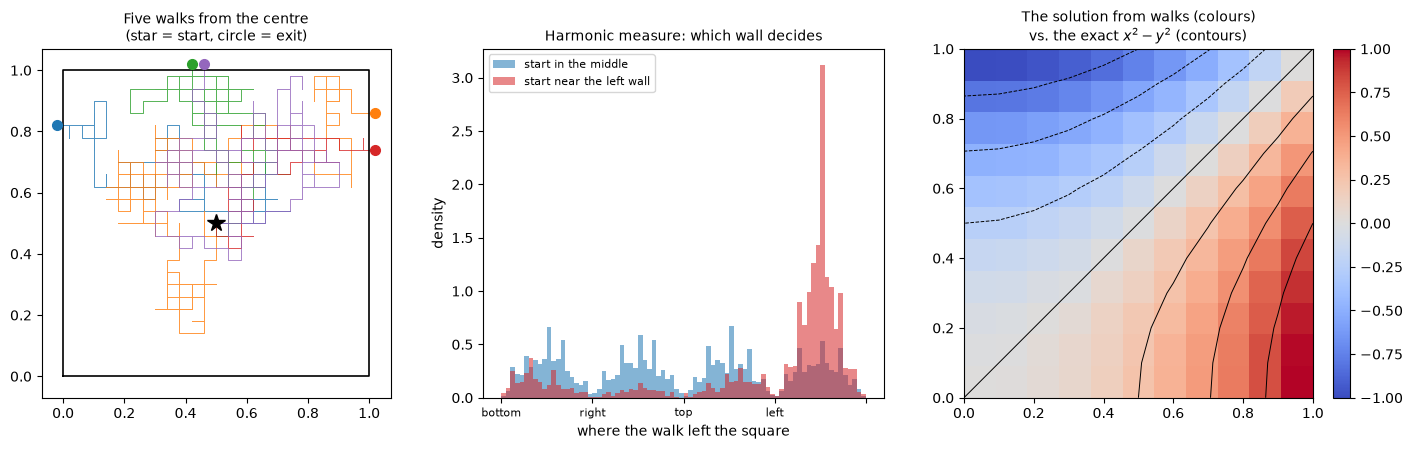

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.5))

# left: a few walks
ax = axes[0]
h_fig = 1 / 25
for color in ("tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"):
    x, y = 0.5, 0.5
    path = [(x, y)]
    while 0 < x < 1 and 0 < y < 1:
        direction = random.randrange(4)
        x += h_fig * (1 if direction == 0 else -1 if direction == 1 else 0)
        y += h_fig * (1 if direction == 2 else -1 if direction == 3 else 0)
        x, y = round(x, 9), round(y, 9)
        path.append((x, y))
    ax.plot(*zip(*path), lw=0.7, alpha=0.8, color=color)
    ax.plot([path[-1][0]], [path[-1][1]], "o", ms=7, color=color,
            clip_on=False, zorder=5)          # the exit lies on the boundary, otherwise half of it would be clipped
ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "k", lw=1.2)
ax.plot([0.5], [0.5], "k*", ms=13, zorder=6)
ax.set_xlim(-0.07, 1.07); ax.set_ylim(-0.07, 1.07)
ax.set_aspect("equal")
ax.set_title("Five walks from the centre\n(star = start, circle = exit)", fontsize=10)

# middle: where the walks exit
ax = axes[1]
for (sx, sy), color, label in (((0.5, 0.5), "tab:blue", "start in the middle"),
                               ((0.15, 0.5), "tab:red", "start near the left wall")):
    exits = []
    for _ in range(4000):
        x, y = sx, sy
        while 0 < x < 1 and 0 < y < 1:
            direction = random.randrange(4)
            x += h_fig * (1 if direction == 0 else -1 if direction == 1 else 0)
            y += h_fig * (1 if direction == 2 else -1 if direction == 3 else 0)
            x, y = round(x, 9), round(y, 9)
        # a perimeter coordinate 0..4 going around the square
        if y <= 0:
            s_ = x
        elif x >= 1:
            s_ = 1 + y
        elif y >= 1:
            s_ = 2 + (1 - x)
        else:
            s_ = 3 + (1 - y)
        exits.append(s_)
    ax.hist(exits, bins=80, range=(0, 4), density=True, alpha=0.55, color=color, label=label)
ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(["bottom", "right", "top", "left", ""], fontsize=8)
ax.set_xlabel("where the walk left the square")
ax.set_ylabel("density")
ax.set_title("Harmonic measure: which wall decides", fontsize=10)
ax.legend(fontsize=8)

# right: the whole solution on a coarse lattice
ax = axes[2]
m_grid = 11
h_grid = 1 / (m_grid - 1)
field = [[0.0] * m_grid for _ in range(m_grid)]
for i in range(m_grid):
    for j in range(m_grid):
        x, y = i * h_grid, j * h_grid
        if i in (0, m_grid - 1) or j in (0, m_grid - 1):
            field[j][i] = g_harmonic(x, y)
        else:
            field[j][i] = lattice_walk(x, y, h_grid, g_harmonic, N=4000)[0]
im = ax.imshow(field, origin="lower", extent=(0, 1, 0, 1), cmap="coolwarm")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.contour(
    [i * h_grid for i in range(m_grid)], [j * h_grid for j in range(m_grid)],
    [[g_harmonic(i * h_grid, j * h_grid) for i in range(m_grid)] for j in range(m_grid)],
    levels=8, colors="k", linewidths=0.7)
ax.set_title("The solution from walks (colours)\nvs. the exact $x^2-y^2$ (contours)", fontsize=10)

plt.tight_layout()
plt.show()

The right-hand picture is the whole solution assembled from independent walks at every node — the
colours sit on the contours of the exact solution.

At the same time it shows the **main weakness**: we had to run walks separately at each of the 81
interior nodes. If we want the whole solution on a fine lattice, a relaxation method is incomparably
better. The walk pays off when you want **the value at one point** (or at a few points) — exactly as
with systems of equations.

## 3. The Poisson equation

With a source on the right-hand side,

$$\Delta u = f \ \text{ in } G, \qquad u = g \ \text{ on } \partial G,$$

the discrete relation changes to

$$u_{ij} = \frac{1}{4}\sum_{\text{neighbours}} u - \frac{h^2}{4}f_{ij},$$

so besides the final value $g$ the walk **collects a contribution $-\tfrac{h^2}{4}f$ at every visited
node**:

$$u(x) = E\Big[\,g(X_T) - \frac{h^2}{4}\sum_{k=0}^{T-1} f(X_k)\,\Big].$$

Physically: the boundary condition is what flows in from outside, and the sum along the path is what
gets produced on the way.

A check: $u = x^2 + y^2$ gives $\Delta u = 4$, so we take $f \equiv 4$.

In [4]:
def g_poisson(x, y):
    return x * x + y * y


print("The Poisson equation Δu = 4, u = x² + y² on the boundary")
print(f"{'point':>14s} {'walk':>22s} {'exact':>10s}")
for px, py in ((0.5, 0.5), (0.25, 0.75), (0.1, 0.2)):
    m, se, _ = lattice_walk(px, py, h, g_poisson, f=lambda x, y: 4.0)
    print(f"({px:.2f}, {py:.2f}) {m:>14.5f} +- {se:<6.5f} {g_poisson(px, py):>10.5f}")
    assert abs(m - g_poisson(px, py)) < 5 * se

The Poisson equation Δu = 4, u = x² + y² on the boundary
         point                   walk      exact


(0.50, 0.50)        0.50043 +- 0.00410    0.50000


(0.25, 0.75)        0.62744 +- 0.00333    0.62500


(0.10, 0.20)        0.04844 +- 0.00145    0.05000


## 4. The walk on spheres

The walk on a lattice has two annoyances: it needs a lattice (and that introduces a discretization
error), and the number of steps grows like $1/h^2$ — halving the lattice step means four times the
work.

**The walk on spheres** (Muller, 1956) sidesteps both and rests on a simple fact:

> If $u$ is harmonic in a ball centred at $x$, then $u(x)$ is the average of $u$ over the surface of
> that ball.

So instead of a little step to a neighbour we can **jump straight to a random point of the largest
ball that fits inside the region** — and the expectation does not change. The algorithm:

1. At the point $x$ find $r = \mathrm{dist}(x, \partial G)$.
2. Jump to a uniformly random point of the sphere of radius $r$ (exercise 8).
3. Repeat while $r > \varepsilon$; then take the nearest boundary point and return $g$ there.

No lattice, and only $O(\log(1/\varepsilon))$ steps are needed instead of $O(1/h^2)$, because every
jump shrinks the distance to the boundary by a constant factor on average.

In [5]:
def distance_to_boundary(x, y):
    return min(x, 1 - x, y, 1 - y)


def nearest_on_boundary(x, y):
    candidates = ((x, 0.0, y), (x, 1.0, 1 - y), (0.0, y, x), (1.0, y, 1 - x))
    bx, by, _ = min(candidates, key=lambda t: t[2])
    return bx, by


def walk_on_spheres(x0, y0, g, N=20_000, eps=1e-3):
    '''The walk on spheres (here circles) for the Laplace equation.'''
    s = s2 = 0.0
    total_jumps = 0
    for _ in range(N):
        x, y, jumps = x0, y0, 0
        while True:
            r = distance_to_boundary(x, y)
            if r < eps:
                break
            angle = 2 * math.pi * random.random()
            x += r * math.cos(angle)
            y += r * math.sin(angle)
            jumps += 1
        v = g(*nearest_on_boundary(x, y))
        s += v
        s2 += v * v
        total_jumps += jumps
    m = s / N
    return m, math.sqrt(max(s2 / N - m * m, 0.0) / N), total_jumps / N


import time

print(f"{'point':>14s} {'method':>12s} {'estimate':>21s} {'exact':>9s} {'steps':>8s} {'time':>8s}")
for px, py in ((0.5, 0.5), (0.25, 0.75)):
    t0 = time.perf_counter()
    m1, se1, k1 = lattice_walk(px, py, h, g_harmonic, N=20_000)
    t1 = time.perf_counter() - t0
    t0 = time.perf_counter()
    m2, se2, k2 = walk_on_spheres(px, py, g_harmonic, N=20_000)
    t2 = time.perf_counter() - t0
    exact_ = g_harmonic(px, py)
    print(f"({px:.2f}, {py:.2f}) {'on a lattice':>12s} {m1:>13.5f} +- {se1:<5.5f} {exact_:>9.5f} {k1:>8.0f} {t1:>7.2f} s")
    print(f"{'':>14s} {'on spheres':>12s} {m2:>13.5f} +- {se2:<5.5f} {exact_:>9.5f} {k2:>8.1f} {t2:>7.2f} s")
    print(f"{'':>14s} {'speed-up':>12s} {t1 / t2:>13.0f}x")

         point       method              estimate     exact    steps     time


(0.50, 0.50) on a lattice      -0.00212 +- 0.00410   0.00000      473    6.46 s
                 on spheres       0.00029 +- 0.00414   0.00000      7.8    0.05 s
                   speed-up           131x


(0.25, 0.75) on a lattice      -0.49959 +- 0.00334  -0.50000      289    3.94 s
                 on spheres      -0.50098 +- 0.00334  -0.50000      8.5    0.05 s
                   speed-up            76x


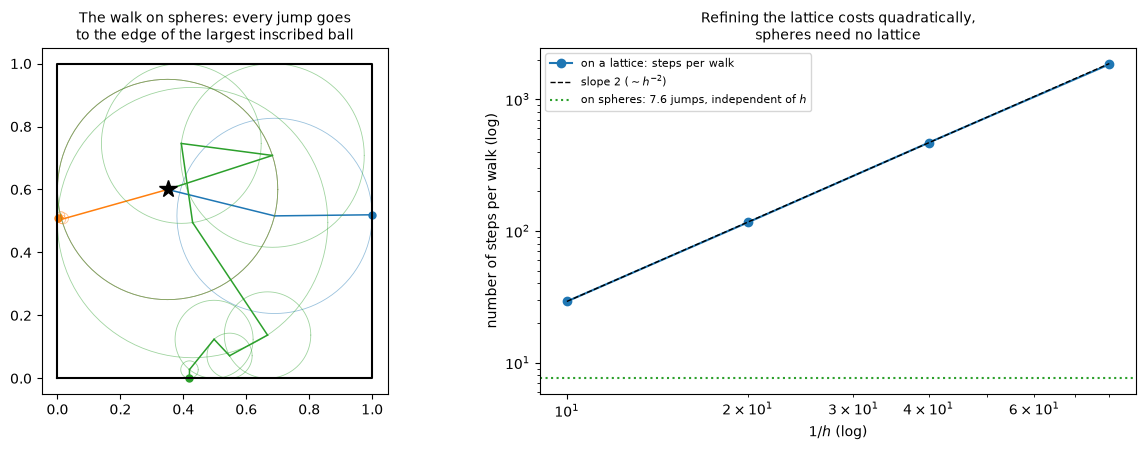

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

ax = axes[0]
for color in ("tab:blue", "tab:orange", "tab:green"):
    x, y = 0.35, 0.6
    for _ in range(12):
        r = distance_to_boundary(x, y)
        if r < 1e-3:
            break
        circle = [(x + r * math.cos(2 * math.pi * t / 100), y + r * math.sin(2 * math.pi * t / 100))
                  for t in range(101)]
        ax.plot(*zip(*circle), lw=0.6, color=color, alpha=0.45)
        angle = 2 * math.pi * random.random()
        nx, ny = x + r * math.cos(angle), y + r * math.sin(angle)
        ax.plot([x, nx], [y, ny], "-", lw=1.1, color=color)
        x, y = nx, ny
    ax.plot([x], [y], "o", ms=5, color=color)
ax.plot([0.35], [0.6], "k*", ms=13)
ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "k", lw=1.5)
ax.set_aspect("equal")
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
ax.set_title("The walk on spheres: every jump goes\nto the edge of the largest inscribed ball", fontsize=10)

ax = axes[1]
hs = [1 / 10, 1 / 20, 1 / 40, 1 / 80]
steps_grid, times_grid = [], []
for hh in hs:
    t0 = time.perf_counter()
    _, _, k = lattice_walk(0.5, 0.5, hh, g_harmonic, N=1500)
    times_grid.append((time.perf_counter() - t0) / 1500)
    steps_grid.append(k)
_, _, k_sph = walk_on_spheres(0.5, 0.5, g_harmonic, N=1500)
t0 = time.perf_counter()
walk_on_spheres(0.5, 0.5, g_harmonic, N=1500)
time_sph = (time.perf_counter() - t0) / 1500

ax.loglog([1 / hh for hh in hs], steps_grid, "o-", label="on a lattice: steps per walk")
ax.loglog([1 / hh for hh in hs], [steps_grid[0] * (1 / hh / (1 / hs[0])) ** 2 for hh in hs], "k--",
          lw=1, label="slope 2 ($\\sim h^{-2}$)")
ax.axhline(k_sph, color="tab:green", ls=":", label=f"on spheres: {k_sph:.1f} jumps, independent of $h$")
ax.set_xlabel("$1/h$ (log)")
ax.set_ylabel("number of steps per walk (log)")
ax.set_title("Refining the lattice costs quadratically,\nspheres need no lattice", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

The right-hand plot sums up the difference: on a lattice the cost grows like $h^{-2}$, with spheres
it is constant — and much smaller besides. In our problem the walk on spheres is two orders of
magnitude faster and has no discretization error.

The price is that we have to be able to compute the **distance to the boundary**. For a square that is
trivial, for a complicated region it is not — and there a lattice may be simpler.

## Summary

| Concept | What to remember |
|---------|------------------|
| The mean-value property | $u_{ij}$ = the average of the four neighbours ⟺ $\Delta u = 0$ discretely |
| The Dirichlet problem | $u(x) = E[\,g(X_T)\,]$, where $X_T$ is the place of exit from the region |
| Harmonic measure | the distribution of the exit point; it decides which part of the boundary matters |
| The Poisson equation | $u(x) = E\big[g(X_T) - \tfrac{h^2}{4}\sum_k f(X_k)\big]$ — collected along the way |
| The cost on a lattice | $O(h^{-2})$ steps per walk; refining is expensive |
| The walk on spheres | a jump to the edge of the largest inscribed ball; $O(\log 1/\varepsilon)$ jumps, no lattice |
| When it pays off | the value at **one point** of a complicated or high-dimensional region |
| When it does not | the whole solution on a fine lattice — relaxation or finite elements win there |

The main idea is the same as with systems of equations: classical methods compute **everything**, a
random walk goes **straight for what you want**. In a low dimension that is wasteful, in a high one it
is the only viable route — and here the circle closes with `ch01_05_when_mc_pays_off`.

### Try it yourself

1. Take a different harmonic function, $u = e^x\sin y$ say, and verify both methods. Why is the
   discretization error on the lattice non-zero now?
2. Measure how the number of jumps in the walk on spheres grows with $\varepsilon$. Does
   $O(\log 1/\varepsilon)$ fit?
3. Solve the problem on an L-shaped region (a square with a corner cut out). What happens to the walk
   on spheres at the inner corner?
4. Extend the lattice walk to three dimensions and measure how the number of steps grows. How does it
   fare against relaxation in 3D?
5. For the Poisson equation try a non-constant $f(x,y) = \sin(\pi x)\sin(\pi y)$ and compare with the
   analytic solution.
6. Compute the solution at one point on a lattice with $h = 1/200$ by both methods and compare the time
   at the same resulting accuracy.